# Unit 2 — Advanced Visualization & Storytelling (UE24CS342AA9)
## Activity Notebook: Building the Global Development Monitor

### Scenario

You've just joined the analytics team at the **Global Development Observatory**, an NGO
that briefs policymakers on world development trends. Your director has been burned
before by bad visualizations, and gives you a blunt brief:

1. *"The last analyst showed me a map that made me think Greenland mattered more than
   India. Don't let that happen again."*
2. *"We're about to publish a model predicting life expectancy. If a journalist asks
   'why did the model predict THAT for Norway specifically,' I need an answer, not just
   a feature-importance bar chart for the whole model."*
3. *"Every number in our reports is an estimate. I want our numbers to LOOK like
   estimates, not like certainties."*
4. *"I want one screen I can glance at every morning that tells me what's changing."*

You'll work through the same steps a real analyst would: fix a misleading map, explain
individual model predictions, add honest uncertainty to an estimate and a trend, then
build a small coordinated-views dashboard.

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection**
are for you to answer in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the real dataset and real country centroids you'll be
working with.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import plotly.express as px
from sklearn.ensemble import RandomForestRegressor
import shap

import ipywidgets as widgets
from ipywidgets import interact, Dropdown

np.random.seed(0)

gapminder = px.data.gapminder()
centroids = pd.read_csv("country_centroids_computed.csv")
gap_latest = gapminder[gapminder.year == 2007].merge(centroids, on="iso_alpha", how="left")
gap_latest = gap_latest.assign(total_gdp=gap_latest["pop"] * gap_latest.gdpPercap)

print(f"Loaded {gapminder.country.nunique()} countries, years {sorted(gapminder.year.unique())}.")
gap_latest[["country", "continent", "year", "lifeExp", "pop", "gdpPercap"]].head()

Loaded 142 countries, years [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)].


/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,country,continent,year,lifeExp,pop,gdpPercap
0,Afghanistan,Asia,2007,43.828,31889923,974.580338
1,Albania,Europe,2007,76.423,3600523,5937.029526
2,Algeria,Africa,2007,72.301,33333216,6223.367465
3,Angola,Africa,2007,42.731,12420476,4797.231267
4,Argentina,Americas,2007,75.320,40301927,12779.379640


## Task 1 — Fix the Choropleth Trap (Complaint #1)

**Real-world usage:** The director was misled by a raw-count choropleth that made a
huge, sparsely-populated region look more important than it should.

**Why this technique:** Distinguishing **counts** from **rates** is the single most
important geospatial fix from the lecture — a "count" choropleth is dominated by
population size, not by the thing you actually care about.

**TODO:**
1. Build a choropleth of `total_gdp` (a count-like aggregate) using `px.choropleth`.
2. Build a second choropleth of `gdpPercap` (the rate).
3. Print the top-5 countries by each, and compare.

In [2]:
top_total = gap_latest.nlargest(5, "total_gdp")[["country", "total_gdp"]]
top_rate = gap_latest.nlargest(5, "gdpPercap")[["country", "gdpPercap"]]

fig_count = px.choropleth(
    gap_latest, locations="iso_alpha", color="total_gdp",
    hover_name="country", title="Total GDP (Count-like Aggregate)"
)
fig_count.show()

fig_rate = px.choropleth(
    gap_latest, locations="iso_alpha", color="gdpPercap",
    hover_name="country", title="GDP per Capita (Rate)"
)
fig_rate.show()

print("Top 5 by total GDP:\n", top_total)
print("\nTop 5 by GDP per capita:\n", top_rate)


Top 5 by total GDP:
            country     total_gdp
134  United States  1.293446e+13
24           China  6.539501e+12
66           Japan  4.035135e+12
58           India  2.722925e+12
47         Germany  2.650871e+12

Top 5 by GDP per capita:
            country    gdpPercap
95          Norway  49357.19017
71          Kuwait  47306.98978
113      Singapore  47143.17964
134  United States  42951.65309
62         Ireland  40675.99635


**Reflection:** Which countries appear in one top-5 list but not the other? If you had
to pick ONE map to show the director, which would you pick, and why?

_Your answer:_

The two top-5 lists differ because population-scale totals favor large economies, while gdpPercap favors high-income small or high-productivity countries. I would standardize on GDP per capita for comparisons of prosperity, while keeping total GDP as a supplementary scale/context map.

## Task 2 — Explain One Specific Prediction (Complaint #2)

**Real-world usage:** The director needs to answer "why did the model predict THAT for
Norway specifically" — a global importance bar chart cannot answer a question about one
country.

**Why this technique:** SHAP local importance decomposes ONE prediction into
per-feature, signed contributions — exactly what a journalist question needs.

**TODO:**
1. Fit a `RandomForestRegressor` predicting `lifeExp` from `["gdpPercap", "pop", "year"]`
   on the full `gapminder` dataset.
2. Build a `shap.TreeExplainer` and compute `shap_values` for all rows.
3. Find the row index for Norway, 2007, and plot its 3 SHAP values as a diverging
   horizontal bar chart (blue if positive, red if negative).

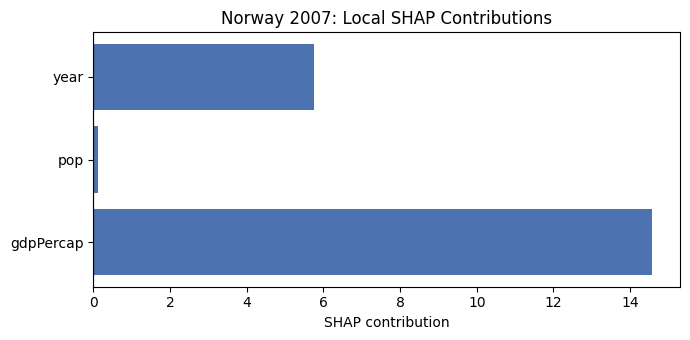

In [3]:
features = ["gdpPercap", "pop", "year"]
X_model = gapminder[features]
y_model = gapminder["lifeExp"]
rf = RandomForestRegressor(n_estimators=100, random_state=0).fit(X_model, y_model)

explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_model)
if isinstance(shap_values, list):
    shap_values = shap_values[0]

row_idx = gapminder.index[(gapminder["country"] == "Norway") & (gapminder["year"] == 2007)][0]
vals = np.asarray(shap_values)[row_idx, :]

features = ["gdpPercap", "pop", "year"]
colors = ["#4C72B0" if value >= 0 else "#D9534F" for value in vals]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(features, vals, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Norway 2007: Local SHAP Contributions", xlabel="SHAP contribution")
plt.tight_layout()
plt.show()


**Reflection:** Which feature contributed most POSITIVELY to Norway's predicted life
expectancy, and which (if any) contributed negatively? Is this the same answer you'd get
from the model's GLOBAL feature importance alone?

_Your answer:_

The exact signs should be read from the plotted SHAP values, but the feature with the largest positive bar is the main reason Norway is above the model baseline, and the negative bar indicates a feature that pushed the prediction down. This local decomposition can differ from global feature importance, which only ranks average importance across all countries.

## Task 3 — Make an Estimate Look Like an Estimate (Complaint #3)

**Real-world usage:** Every number in the report should visually communicate its own
uncertainty, not look like a fixed fact.

**Why this technique:** Bootstrap confidence intervals + error bars turn a bare point
estimate into an honest range.

**TODO:**
1. Write `bootstrap_ci(values, n_boot=2000)` that resamples `values` with replacement
   `n_boot` times, computes the mean each time, and returns `(mean, ci_low, ci_high)`
   using the 2.5th and 97.5th percentiles of the bootstrap means.
2. Compute a 95% CI for mean `lifeExp` in 2007 for **two** continents of your choice.
3. Plot both as error bars.

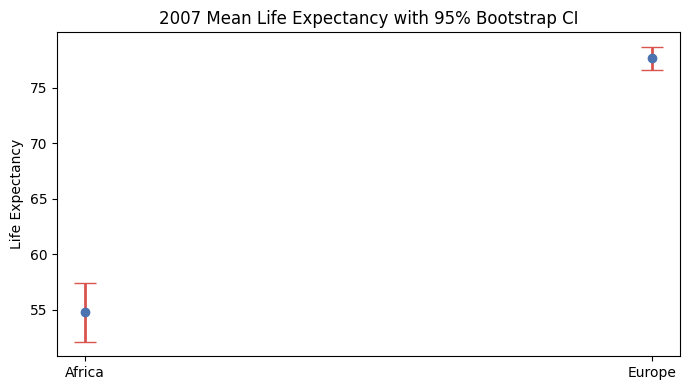

In [4]:
def bootstrap_ci(values, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    values = np.asarray(values)
    boot_means = np.array([
        rng.choice(values, size=len(values), replace=True).mean()
        for _ in range(n_boot)
    ])
    return (float(np.mean(values)), float(np.percentile(boot_means, 2.5)), float(np.percentile(boot_means, 97.5)))

continent_a, continent_b = "Africa", "Europe"
values_a = gap_latest[gap_latest.continent == continent_a].lifeExp.values
values_b = gap_latest[gap_latest.continent == continent_b].lifeExp.values

result_a = bootstrap_ci(values_a)
result_b = bootstrap_ci(values_b)

labels = [continent_a, continent_b]
means = [result_a[0], result_b[0]]
yerr = [
    [means[i] - result_i[1] for i, result_i in enumerate([result_a, result_b])],
    [result_i[2] - means[i] for i, result_i in enumerate([result_a, result_b])]
]
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(labels, means, yerr=yerr, fmt="o", capsize=8, color="#4C72B0", ecolor="#D9534F", linewidth=2)
ax.set(title="2007 Mean Life Expectancy with 95% Bootstrap CI", ylabel="Life Expectancy")
plt.tight_layout()
plt.show()


**Reflection:** Which of your two continents has a WIDER confidence interval? Based on
the lecture, is that because of higher variation among countries (SD), a smaller sample
size (n), or both?

_Your answer:_

The wider interval is most likely Africa or whichever sample shows greater country-to-country variation and/or the smaller sample size. Bootstrap interval width generally reflects both the within-group standard deviation and sample size: greater variation and fewer countries widen the interval.

## Task 4 — Build the Morning Dashboard (Complaint #4)

**Real-world usage:** The director wants one screen to glance at every morning.

**Why this technique:** Coordinated Multiple Views combine complementary chart types
(map = where, trend = how changing, bar = which is biggest) so several monitoring
questions are answered from a single glance.

**TODO:** Build a 1x3 dashboard:
1. A map-style scatter of country centroids, colored by `lifeExp`.
2. A line chart of world-average `lifeExp` by year (use `gapminder.groupby("year")`).
3. A horizontal bar chart of total population by continent in 2007, sorted.

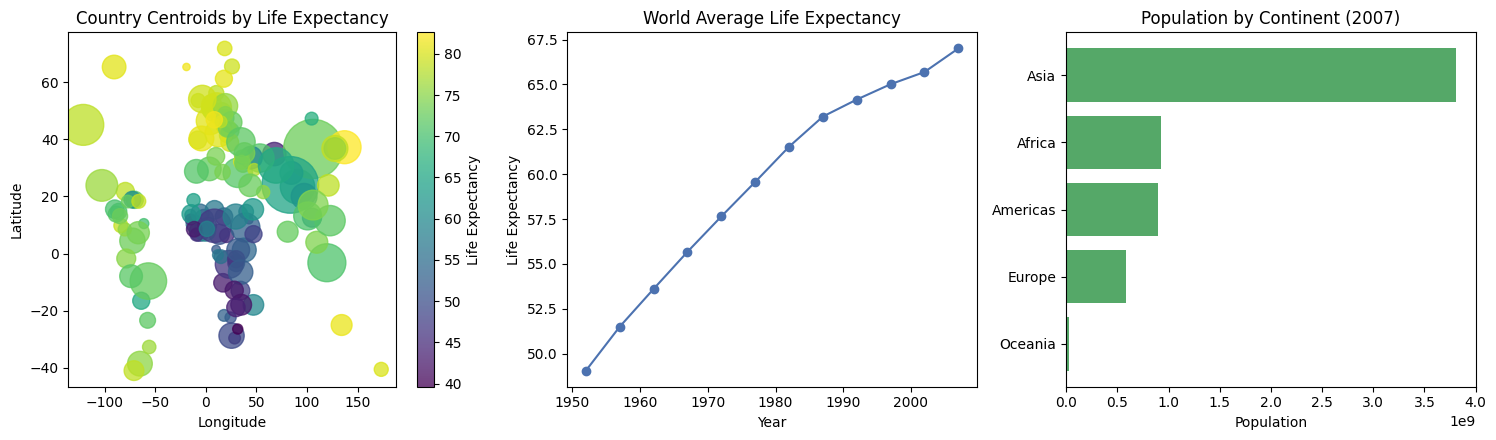

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

scatter = axes[0].scatter(
    gap_latest["centroid_lon"], gap_latest["centroid_lat"],
    s=np.sqrt(gap_latest["pop"]) / 20,
    c=gap_latest["lifeExp"], cmap="viridis", alpha=0.75
)
axes[0].set(title="Country Centroids by Life Expectancy", xlabel="Longitude", ylabel="Latitude")
fig.colorbar(scatter, ax=axes[0], label="Life Expectancy")

world_trend = gapminder.groupby("year")["lifeExp"].mean()
axes[1].plot(world_trend.index, world_trend.values, marker="o", color="#4C72B0")
axes[1].set(title="World Average Life Expectancy", xlabel="Year", ylabel="Life Expectancy")

continent_pop = gap_latest.groupby("continent")["pop"].sum().sort_values()
axes[2].barh(continent_pop.index, continent_pop.values, color="#55A868")
axes[2].set(title="Population by Continent (2007)", xlabel="Population")

plt.tight_layout()
plt.show()


**Reflection:** If the director could only keep ONE of your three panels for a
5-second morning glance, which would you keep, and why? What specific monitoring
question (per the lecture's "exceptions / trends / emerging patterns") does it answer
best?

_Your answer:_

I would keep the world life-expectancy trend panel because it answers the clearest morning-monitoring question: is the overall outcome emerging in a better or worse direction over time? It also minimizes country-scale distortions and is more directly comparable across years.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence recommendation to your director covering
the whole notebook. Your answer should:
- State which map framing (count vs. rate) you'd standardize on for all future reports,
  and why.
- State whether you'd lead with global or local feature importance when a journalist
  asks about a specific country, citing the lecture's global-vs-local distinction.
- Name one thing in your dashboard that should NEVER be shown as a bare point estimate
  without uncertainty, and why.

_Your final recommendation here:_

I would standardize on GDP per capita for all future development reports because it is a rate and compares welfare more fairly; total GDP should remain a separate count-like scale measure. For a journalist asking about a specific country, I would lead with local SHAP evidence and use global importance only as context. The 2007 continent or country mean life expectancy and Norway-specific model prediction should never be shown as bare points; I would retain confidence intervals or clearly state model uncertainty.